In [2]:
 #Part 1: Proposal - Academic Stress levels 
#can condense coping strategies down using for loop
#clean up the data
#date time to datetime
#study environment to 5 point system
#peer pressure vs academic stress index
#academic pressure (home) vs acamdeic stress index
#study environemnt vs academic stress
#high school student vs undergrads

In [ ]:
#important data: 
#numeric cols = ['Peerpressure', 'AcademicPressure(home)', 'AcademicCompetitionScore']
#categorical cols = ['AcademicStage', 'StudyEnvironment', 'CopingStrategy', 'Smoking,Drinking,Others?']


In [3]:
import pandas as pd
stress_level = '/Users/daniellamori/Desktop/Proyecto USF/Academic-stress-levels-/academic Stress level - maintainance 1 2.csv'
df = pd.read_csv(stress_level)

In [4]:
df.head()

,Timestamp,Your Academic Stage,Peer pressure,Academic pressure from your home,Study Environment,What coping strategy you use as a student?,"Do you have any bad habits like smoking, drinking on a daily basis?",What would you rate the academic competition in your student life,Rate your academic stress index
0,24/07/2025 22:05:39,undergraduate,4,5,Noisy,Analyze the situation and handle it with intel...,No,3,5
1,24/07/2025 22:05:52,undergraduate,3,4,Peaceful,Analyze the situation and handle it with intel...,No,3,3
2,24/07/2025 22:06:39,undergraduate,1,1,Peaceful,"Social support (friends, family)",No,2,4
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
4,24/07/2025 22:08:06,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,5


In [49]:
df['AcademicStage'].value_counts()
#Can be skewed here - most data on undergrad

AcademicStage
undergraduate    100
high school       29
post-graduate     11
Name: count, dtype: int64

In [6]:
print(df.columns.tolist())

['Timestamp', 'Your Academic Stage', 'Peer pressure', 'Academic pressure from your home', 'Study Environment', 'What coping strategy you use as a student?', 'Do you have any bad habits like smoking, drinking on a daily basis?', 'What would you rate the academic  competition in your student life', 'Rate your academic stress index ']


In [17]:
df.shape

(140, 9)

In [18]:
df.columns

Index(['Timestamp', 'Your Academic Stage', 'Peer pressure',
       'Academic pressure from your home', 'Study Environment',
       'What coping strategy you use as a student?',
       'Do you have any bad habits like smoking, drinking on a daily basis?',
       'What would you rate the academic  competition in your student life',
       'Rate your academic stress index '],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140 entries, 0 to 139
Data columns (total 9 columns):
 #   Column                                                               Non-Null Count  Dtype
---  ------                                                               --------------  -----
 0   Timestamp                                                            140 non-null    str  
 1   Your Academic Stage                                                  140 non-null    str  
 2   Peer pressure                                                        140 non-null    int64
 3   Academic pressure from your home                                     140 non-null    int64
 4   Study Environment                                                    139 non-null    str  
 5   What coping strategy you use as a student?                           140 non-null    str  
 6   Do you have any bad habits like smoking, drinking on a daily basis?  140 non-null    str  
 7   What would you rate the academic  comp

In [19]:
df.columns = df.columns.str.replace('Your Academic Stage','AcademicStage')
df.columns = df.columns.str.replace('Academic pressure from your home','AcademicPressure(home)')
df.columns = df.columns.str.replace('What coping strategy you use as a student?','CopingStrategy')
df.columns = df.columns.str.replace('Do you have any bad habits like smoking, drinking on a daily basis?','Smoking,Drinking,Others?')
df.columns = df.columns.str.replace('What would you rate the academic  competition in your student life','AcademicCompetitionScore')
df.columns = df.columns.str.replace('Rate your academic stress index ','AcademicStressIndex')
df.columns = df.columns.str.replace(' ','')
df.columns

Index(['Timestamp', 'AcademicStage', 'Peerpressure', 'AcademicPressure(home)',
       'StudyEnvironment', 'CopingStrategy', 'Smoking,Drinking,Others?',
       'AcademicCompetitionScore', 'AcademicStressIndex'],
      dtype='str')

In [20]:
df.head()

,Timestamp,AcademicStage,Peerpressure,AcademicPressure(home),StudyEnvironment,CopingStrategy,"Smoking,Drinking,Others?",AcademicCompetitionScore,AcademicStressIndex
0,24/07/2025 22:05:39,undergraduate,4,5,Noisy,Analyze the situation and handle it with intel...,No,3,5
1,24/07/2025 22:05:52,undergraduate,3,4,Peaceful,Analyze the situation and handle it with intel...,No,3,3
2,24/07/2025 22:06:39,undergraduate,1,1,Peaceful,"Social support (friends, family)",No,2,4
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Analyze the situation and handle it with intel...,No,4,3
4,24/07/2025 22:08:06,undergraduate,3,3,Peaceful,Analyze the situation and handle it with intel...,No,4,5


In [21]:
df.describe()
#does not really show much

,Peerpressure,AcademicPressure(home),AcademicCompetitionScore,AcademicStressIndex
count,140.000000,140.000000,140.000000,140.000000
mean,3.071429,3.178571,3.492857,3.721429
std,1.083844,1.276618,1.028349,1.032339
min,1.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,3.000000,3.000000
50%,3.000000,3.000000,4.000000,4.000000
75%,4.000000,4.000000,4.000000,4.000000
max,5.000000,5.000000,5.000000,5.000000


In [22]:
df.isna().sum()
#only one NaN value in study environment column

Timestamp                   0
AcademicStage               0
Peerpressure                0
AcademicPressure(home)      0
StudyEnvironment            1
CopingStrategy              0
Smoking,Drinking,Others?    0
AcademicCompetitionScore    0
AcademicStressIndex         0
dtype: int64

In [24]:
df['StudyEnvironment'].unique()

<ArrowStringArray>
['Noisy', 'Peaceful', 'disrupted', nan]
Length: 4, dtype: str

In [26]:
df[df['StudyEnvironment'].isna()]
#only one NaN value in study environment column
#the data might have been corrupted when logging
#the data might have been an invalid data type 



,Timestamp,AcademicStage,Peerpressure,AcademicPressure(home),StudyEnvironment,CopingStrategy,"Smoking,Drinking,Others?",AcademicCompetitionScore,AcademicStressIndex
129,12/08/2025 12:13:46,undergraduate,5,5,NaN,Emotional breakdown (crying a lot),No,5,4


In [28]:
df['CopingStrategy'].unique()

<ArrowStringArray>
['Adaptability', 'Socialize', 'Emotional']
Length: 3, dtype: str

In [29]:
df['CopingStrategy'] = df['CopingStrategy'].replace('Analyze the situation and handle it with intellect', 'Adaptability')
df['CopingStrategy'] = df['CopingStrategy'].replace('Social support (friends, family)', 'Socialize')
df['CopingStrategy'] = df['CopingStrategy'].replace('Emotional breakdown (crying a lot)', 'Emotional')
df['CopingStrategy'].unique()

<ArrowStringArray>
['Adaptability', 'Socialize', 'Emotional']
Length: 3, dtype: str

In [30]:
df.head(5)

,Timestamp,AcademicStage,Peerpressure,AcademicPressure(home),StudyEnvironment,CopingStrategy,"Smoking,Drinking,Others?",AcademicCompetitionScore,AcademicStressIndex
0,24/07/2025 22:05:39,undergraduate,4,5,Noisy,Adaptability,No,3,5
1,24/07/2025 22:05:52,undergraduate,3,4,Peaceful,Adaptability,No,3,3
2,24/07/2025 22:06:39,undergraduate,1,1,Peaceful,Socialize,No,2,4
3,24/07/2025 22:06:45,undergraduate,3,2,Peaceful,Adaptability,No,4,3
4,24/07/2025 22:08:06,undergraduate,3,3,Peaceful,Adaptability,No,4,5


In [32]:
df['Timestamp'].dtype
df['Tiimestamp'] = pd.to_datetime(df['Timestamp'])
df['Tiimestamp']


/var/folders/cd/tp42ms6j4tb2qwt5jtfzf_gm0000gn/T/ipykernel_71914/2882689222.py:2: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Tiimestamp'] = pd.to_datetime(df['Timestamp'])


0     2025-07-24 22:05:39
1     2025-07-24 22:05:52
2     2025-07-24 22:06:39
3     2025-07-24 22:06:45
4     2025-07-24 22:08:06
              ...        
135   2025-08-17 13:02:04
136   2025-08-18 14:36:00
137   2025-08-18 17:13:52
138   2025-08-18 19:08:52
139   2025-08-18 22:40:13
Name: Tiimestamp, Length: 140, dtype: datetime64[us]

In [33]:
df['Tiimestamp']

0     2025-07-24 22:05:39
1     2025-07-24 22:05:52
2     2025-07-24 22:06:39
3     2025-07-24 22:06:45
4     2025-07-24 22:08:06
              ...        
135   2025-08-17 13:02:04
136   2025-08-18 14:36:00
137   2025-08-18 17:13:52
138   2025-08-18 19:08:52
139   2025-08-18 22:40:13
Name: Tiimestamp, Length: 140, dtype: datetime64[us]

In [39]:
print(df.dtypes)

Timestamp                              str
AcademicStage                          str
Peerpressure                         int64
AcademicPressure(home)               int64
StudyEnvironment                       str
CopingStrategy                         str
Smoking,Drinking,Others?               str
AcademicCompetitionScore             int64
AcademicStressIndex                  int64
Tiimestamp                  datetime64[us]
dtype: object


<Axes: title={'center': 'Frequency of Academic Stress Index'}, xlabel='AcademicStressIndex', ylabel='Frequency'>

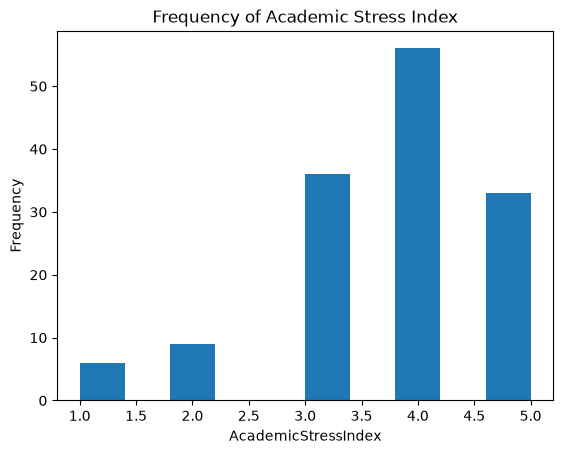

In [43]:
df['AcademicStressIndex'].plot.hist(
    bins=10,
    title='Frequency of Academic Stress Index',
    xlabel='AcademicStressIndex'
)

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

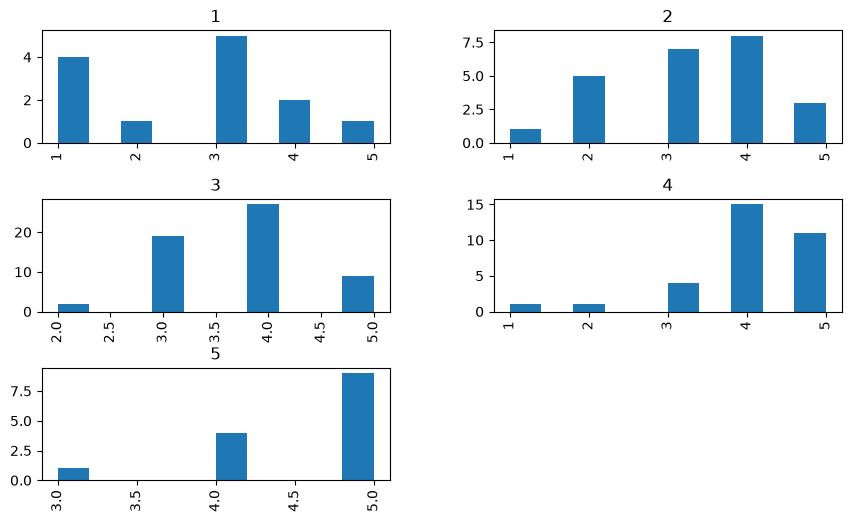

In [46]:
df.hist(column='AcademicStressIndex', by='Peerpressure', bins=10, figsize=(10, 6))

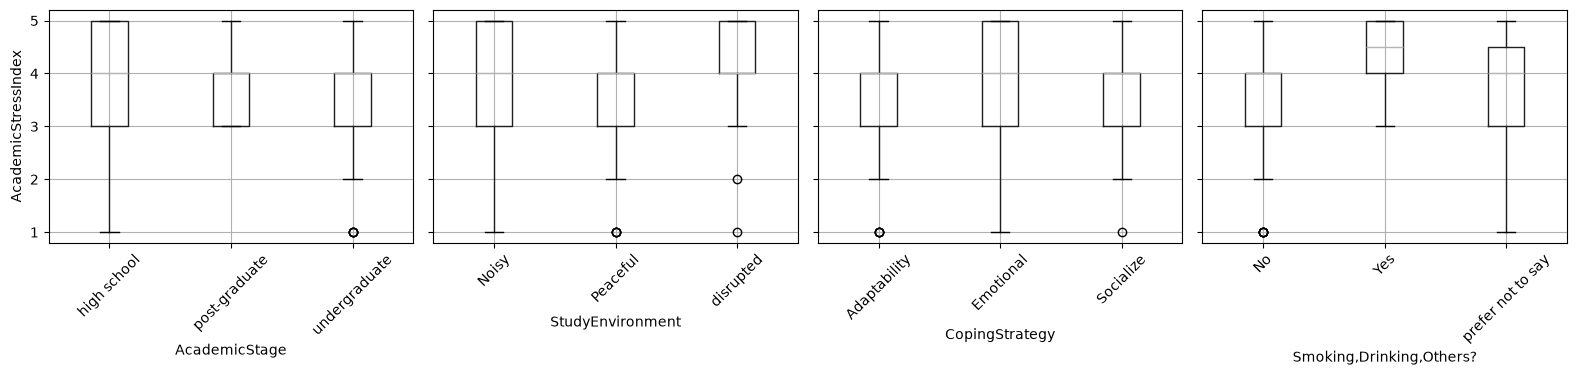

In [48]:
import matplotlib.pyplot as plt

cat_cols = ['AcademicStage', 'StudyEnvironment', 'CopingStrategy', 'Smoking,Drinking,Others?']


# Categorical: box plots
fig, axes = plt.subplots(1, len(cat_cols), figsize=(16, 4), sharey=True)
for ax, col in zip(axes, cat_cols):
    df.boxplot(column='AcademicStressIndex', by=col, ax=ax)
    ax.set_title('')
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('AcademicStressIndex')
fig.suptitle('')
plt.tight_layout()
plt.show()

In [35]:
#Impact missing data: 
#a grades column would have been good, but students might not be willing to share their grades
#a relationship status column would have been good but studnets might not be willing to share 
#information about their private life
#an hours studies column could have been used to figure out some correlation between hours 
#studies and stressindex but students might inflate the numbers
#the data entries in this dataset should be taken with a grain of salt as the data is collected
#from high school and undergraduates and may not be entirely correct
#For undergrad students, a major column would be useful.

#How might data be skewed: 
#There is more data on undergraduates 
#no major listed 
# Coping mechanism might be to general (eg. binge eating) 
